# Video Classification: ResNet / ViT / VisionMamba  ×  Mamba Temporal

Three encoder backbones, all paired with a **Mamba** temporal model:

| Model | Encoder | Temporal |
|-------|---------|----------|
| A | ResNet-18 | Mamba |
| B | ViT-B/16 | Mamba |
| C | Vision Mamba (bidirectional) | Mamba |

After training, penultimate-layer features are extracted and visualised with **t-SNE** and **UMAP**.

## 0 · Dependencies
Run the cell below once if `umap-learn` is not yet installed.

In [1]:
# !pip install scikit-learn

## 1 · Imports

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights, ViT_B_16_Weights
from PIL import Image
from collections import defaultdict

from sklearn.manifold import TSNE
import umap

from mamba_ssm import Mamba

/home/imvikranth/miniconda3/envs/mamba310/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2 · Configuration

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
FRAMES_PER_VIDEO = 7
BATCH_SIZE       = 8
IMG_SIZE         = 128   # ResNet / VisionMamba input
EPOCHS           = 10
LR               = 1e-4

TRAIN_DIR = "/home/imvikranth/mini_project/frame_dataset/train"
VAL_DIR   = "/home/imvikranth/mini_project/frame_dataset/val"

# How many val samples to collect for visualisation (set None = all)
VIZ_MAX_SAMPLES = 500

## 3 · Dataset

In [5]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

In [6]:
class VideoFrameDataset(Dataset):
    """root_dir/<class>/<video>_f<N>.jpg  →  (T, C, H, W), label"""

    def __init__(self, root_dir, transform=None, frames_per_video=7):
        self.samples  = []
        self.transform = transform

        classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        self.idx_to_class = {i: c for c, i in self.class_to_idx.items()}

        for cls in classes:
            cls_path = os.path.join(root_dir, cls)
            if not os.path.isdir(cls_path):
                continue
            videos = defaultdict(list)
            for img in sorted(os.listdir(cls_path)):
                videos[img.split("_f")[0]].append(img)
            for frames in videos.values():
                frames = sorted(frames)[:frames_per_video]
                if len(frames) < frames_per_video:
                    continue
                paths = [os.path.join(cls_path, f) for f in frames]
                self.samples.append((paths, self.class_to_idx[cls]))

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        paths, label = self.samples[idx]
        frames = []
        for p in paths:
            img = Image.open(p).convert("RGB")
            if self.transform:
                img = self.transform(img)
            frames.append(img)
        return torch.stack(frames), label

In [7]:
train_dataset = VideoFrameDataset(TRAIN_DIR, transform, FRAMES_PER_VIDEO)
val_dataset   = VideoFrameDataset(VAL_DIR,   transform, FRAMES_PER_VIDEO)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

num_classes    = len(train_dataset.class_to_idx)
idx_to_class   = train_dataset.idx_to_class
print(f"Classes: {num_classes}  |  Train: {len(train_dataset)}  |  Val: {len(val_dataset)}")

Classes: 101  |  Train: 10055  |  Val: 1673


## 4 · Encoder Backbones

In [8]:
class ResNetEncoder(nn.Module):
    """ResNet-18  →  512-d GAP feature."""
    out_dim = 512

    def __init__(self):
        super().__init__()
        base = models.resnet18(weights=ResNet18_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(base.children())[:-1])  # drop FC

    def forward(self, x):          # (B, 3, H, W)
        return self.backbone(x).flatten(1)  # (B, 512)

In [9]:
class ViTEncoder(nn.Module):
    """ViT-B/16  →  768-d CLS token.  Resizes to 224×224 internally."""
    out_dim = 768

    def __init__(self):
        super().__init__()
        self.vit = models.vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
        self.vit.heads = nn.Identity()   # remove classification head

    def forward(self, x):          # (B, 3, H, W)
        if x.shape[-2:] != (224, 224):
            x = torch.nn.functional.interpolate(
                x, size=(224, 224), mode="bilinear", align_corners=False
            )
        return self.vit(x)         # (B, 768)

In [10]:
class VisionMambaEncoder(nn.Module):
    """Bidirectional Vision Mamba: fwd scan + bwd scan summed  →  128-d."""
    out_dim = 128

    def __init__(self, d_model=128, patch_size=16):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, d_model, kernel_size=patch_size, stride=patch_size)
        self.mamba_fwd   = Mamba(d_model=d_model)
        self.mamba_bwd   = Mamba(d_model=d_model)
        self.norm        = nn.LayerNorm(d_model)

    def forward(self, x):                          # (B, 3, H, W)
        x   = self.patch_embed(x)                  # (B, D, H', W')
        x   = x.flatten(2).transpose(1, 2)         # (B, N, D)
        fwd = self.mamba_fwd(x)
        bwd = torch.flip(self.mamba_bwd(torch.flip(x, [1])), [1])
        x   = self.norm(fwd + bwd)
        return x.mean(dim=1)                       # (B, 128)

## 5 · VideoModel  (Encoder + Mamba Temporal)

In [11]:
ENCODER_REGISTRY = {
    "resnet": ResNetEncoder,
    "vit"   : ViTEncoder,
    "vmamba": VisionMambaEncoder,
}


class VideoModel(nn.Module):
    """
    Spatial encoder  →  Mamba temporal model  →  classifier.

    The penultimate feature (before the linear head) is accessible via
    `model.penultimate`  after each forward pass — used for visualisation.

    Input : (B, T, C, H, W)
    Output: (B, num_classes)
    """

    def __init__(self, encoder_name: str, num_classes: int):
        super().__init__()

        if encoder_name not in ENCODER_REGISTRY:
            raise ValueError(f"Unknown encoder '{encoder_name}'")

        self.encoder_name = encoder_name
        self.encoder      = ENCODER_REGISTRY[encoder_name]()
        d_model           = self.encoder.out_dim

        # Mamba temporal model
        self.temporal     = Mamba(d_model=d_model)
        self.norm         = nn.LayerNorm(d_model)

        # Linear head  — the input to this is the "penultimate" feature
        self.head         = nn.Linear(d_model, num_classes)

        # Populated during forward; used by extract_features()
        self.penultimate: torch.Tensor | None = None

    def forward(self, x):               # (B, T, C, H, W)
        B, T, C, H, W = x.shape

        # ① Spatial encoding — process all frames in one batch
        feats = self.encoder(x.view(B * T, C, H, W))   # (B*T, D)
        feats = feats.view(B, T, -1)                    # (B, T, D)

        # ② Temporal modelling
        out   = self.temporal(feats)                    # (B, T, D)
        video_feat = self.norm(out.mean(dim=1))         # (B, D)  ← penultimate

        # Store for visualisation (detached, on CPU)
        self.penultimate = video_feat.detach().cpu()

        return self.head(video_feat)                    # (B, num_classes)

## 6 · Training & Evaluation

In [12]:
def train_model(model: VideoModel) -> VideoModel:
    model     = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR)

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        for videos, labels in train_loader:
            videos, labels = videos.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(videos), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"  Epoch {epoch+1}/{EPOCHS}  loss={total_loss/len(train_loader):.4f}")

    return model


def evaluate(model: VideoModel) -> float:
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for videos, labels in val_loader:
            videos, labels = videos.to(device), labels.to(device)
            preds    = model(videos).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
    acc = correct / total
    print(f"  Val accuracy: {acc:.4f}")
    return acc

## 7 · Feature Extraction for Visualisation

After training we run the model in eval mode over the val set and collect
the **penultimate features** (the `d_model`-dimensional vector right before
the linear head).  These are then projected to 2-D with t-SNE and UMAP.

In [13]:
def extract_features(
    model: VideoModel,
    loader: DataLoader,
    max_samples: int | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Run model over `loader` and collect penultimate features + labels.

    Returns
    -------
    feats  : (N, D)  float32 numpy array
    labels : (N,)    int numpy array
    """
    model.eval()
    all_feats  = []
    all_labels = []

    with torch.no_grad():
        for videos, labels in loader:
            videos = videos.to(device)
            model(videos)                            # populates model.penultimate
            all_feats.append(model.penultimate)      # (B, D) cpu tensor
            all_labels.append(labels)

            if max_samples and sum(f.shape[0] for f in all_feats) >= max_samples:
                break

    feats  = torch.cat(all_feats,  dim=0).numpy()
    labels = torch.cat(all_labels, dim=0).numpy()

    if max_samples:
        feats  = feats[:max_samples]
        labels = labels[:max_samples]

    return feats, labels

In [14]:
def plot_2d_features(
    feats_2d   : np.ndarray,
    labels     : np.ndarray,
    title      : str,
    ax         : plt.Axes,
    n_classes  : int,
    alpha      : float = 0.65,
    point_size : int   = 12,
) -> None:
    """Scatter-plot a 2-D projection coloured by class label."""
    cmap    = cm.get_cmap("tab20", n_classes)
    scatter = ax.scatter(
        feats_2d[:, 0], feats_2d[:, 1],
        c=labels, cmap=cmap,
        s=point_size, alpha=alpha, linewidths=0,
    )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    return scatter


def visualise_features(
    feats     : np.ndarray,
    labels    : np.ndarray,
    model_tag : str,
    n_classes : int,
) -> None:
    """
    Side-by-side t-SNE and UMAP plot for a single model's penultimate features.
    Saves the figure as  <model_tag>_features.png.
    """
    print(f"  Computing t-SNE for {model_tag}...")
    tsne_2d = TSNE(
        n_components=2, perplexity=30, n_iter=1000,
        random_state=42, init="pca"
    ).fit_transform(feats)

    print(f"  Computing UMAP  for {model_tag}...")
    umap_2d = umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1,
        random_state=42
    ).fit_transform(feats)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Penultimate-layer features — {model_tag}",
                 fontsize=13, fontweight="bold", y=1.01)

    sc = plot_2d_features(tsne_2d, labels, "t-SNE", axes[0], n_classes)
    plot_2d_features(umap_2d, labels, "UMAP",  axes[1], n_classes)

    # Shared colour-bar / legend (show first 20 classes to avoid clutter)
    cbar = fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label("Class index", fontsize=9)

    plt.tight_layout()
    fname = f"{model_tag.replace(' ', '_').lower()}_features.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    print(f"  Saved → {fname}")
    plt.show()

## 8 · Train All 3 Configurations

In [15]:
# Only 3 combos — all share Mamba as the temporal model
CONFIGS = [
    "resnet",
    "vit",
    "vmamba",
]

results       = {}   # encoder_name  →  val accuracy
trained_models = {}  # encoder_name  →  trained VideoModel (kept for viz)

In [16]:
# ── RESNET + MAMBA ────────────────────────────────────────────────────
enc = "resnet"
tag = f"{enc.upper()} + MAMBA"
print(f"\n{'='*60}")
print(f"  Training : {tag}")
print(f"{'='*60}")

model    = VideoModel(enc, num_classes)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Trainable params: {n_params:,}")

model            = train_model(model)
acc              = evaluate(model)
results[enc]     = acc

# Free GPU VRAM before next encoder
model.cpu()
torch.cuda.empty_cache()
trained_models[enc] = model

torch.save(model.state_dict(), "resnet_mamba.pth")
print("  Saved → resnet_mamba.pth")

print(f"  Done. GPU memory freed.")


  Training : RESNET + MAMBA
  Trainable params: 12,924,069
  Epoch 1/10  loss=1.7332
  Epoch 2/10  loss=0.4041
  Epoch 3/10  loss=0.2101
  Epoch 4/10  loss=0.1807
  Epoch 5/10  loss=0.1643
  Epoch 6/10  loss=0.1493
  Epoch 7/10  loss=0.1363
  Epoch 8/10  loss=0.1323
  Epoch 9/10  loss=0.1055
  Epoch 10/10  loss=0.1234
  Val accuracy: 0.9199
  Saved → resnet_mamba.pth
  Done. GPU memory freed.


In [17]:
# ── VIT + MAMBA ────────────────────────────────────────────────────
enc = "vit"
tag = f"{enc.upper()} + MAMBA"
print(f"\n{'='*60}")
print(f"  Training : {tag}")
print(f"{'='*60}")

model    = VideoModel(enc, num_classes)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Trainable params: {n_params:,}")

model            = train_model(model)
acc              = evaluate(model)
results[enc]     = acc

# Free GPU VRAM before next encoder
model.cpu()
torch.cuda.empty_cache()
trained_models[enc] = model

torch.save(model.state_dict(), "vit_mamba.pth")
print("  Saved → vit_mamba.pth")

print(f"  Done. GPU memory freed.")


  Training : VIT + MAMBA
  Trainable params: 89,648,741


KeyboardInterrupt: 

In [18]:
# ── VMAMBA + MAMBA ────────────────────────────────────────────────────
enc = "vmamba"
tag = f"{enc.upper()} + MAMBA"
print(f"\n{'='*60}")
print(f"  Training : {tag}")
print(f"{'='*60}")

model    = VideoModel(enc, num_classes)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Trainable params: {n_params:,}")

model            = train_model(model)
acc              = evaluate(model)
results[enc]     = acc

# Free GPU VRAM before next encoder
model.cpu()
torch.cuda.empty_cache()
trained_models[enc] = model

torch.save(model.state_dict(), "vmamba_mamba.pth")
print("  Saved → vmamba_mamba.pth")

print(f"  Done. GPU memory freed.")


  Training : VMAMBA + MAMBA
  Trainable params: 461,413
  Epoch 1/10  loss=4.1170
  Epoch 2/10  loss=3.4725
  Epoch 3/10  loss=2.9891
  Epoch 4/10  loss=2.5382
  Epoch 5/10  loss=2.1143
  Epoch 6/10  loss=1.7292
  Epoch 7/10  loss=1.4113
  Epoch 8/10  loss=1.1346
  Epoch 9/10  loss=0.9199
  Epoch 10/10  loss=0.7388
  Val accuracy: 0.7155
  Saved → vmamba_mamba.pth
  Done. GPU memory freed.


## 9 · Results Summary

In [19]:
print("\n" + "="*45)
print(f"{'Encoder':<12} {'Temporal':<10} {'Val Acc':>10}")
print("-"*45)
for enc, acc in sorted(results.items(), key=lambda kv: -kv[1]):
    print(f"{enc:<12} {'mamba':<10} {acc:>10.4f}")
best = max(results, key=results.get)
print("="*45)
print(f"Best  →  {best.upper()} + MAMBA  ({results[best]:.4f})")


Encoder      Temporal      Val Acc
---------------------------------------------
resnet       mamba          0.9199
vmamba       mamba          0.7155
Best  →  RESNET + MAMBA  (0.9199)


## 10 · Penultimate-Layer Feature Visualisation

For each trained model we:
1. Run the val set through the model to collect the **penultimate feature vectors** (`D`-dimensional, right before the linear head)
2. Project to 2-D with **t-SNE** (neighbourhood-preserving) and **UMAP** (global structure-preserving)
3. Colour each point by its true class label

Well-separated clusters → the encoder+temporal stack has learned discriminative representations.


Extracting features: RESNET + MAMBA
  Feature matrix: (500, 512)  |  Labels: (500,)
  Computing t-SNE...
  Computing UMAP...


/home/imvikranth/miniconda3/envs/mamba310/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_40983/405833384.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", num_classes)
/tmp/ipykernel_40983/405833384.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


  Saved → resnet_mamba_features.png


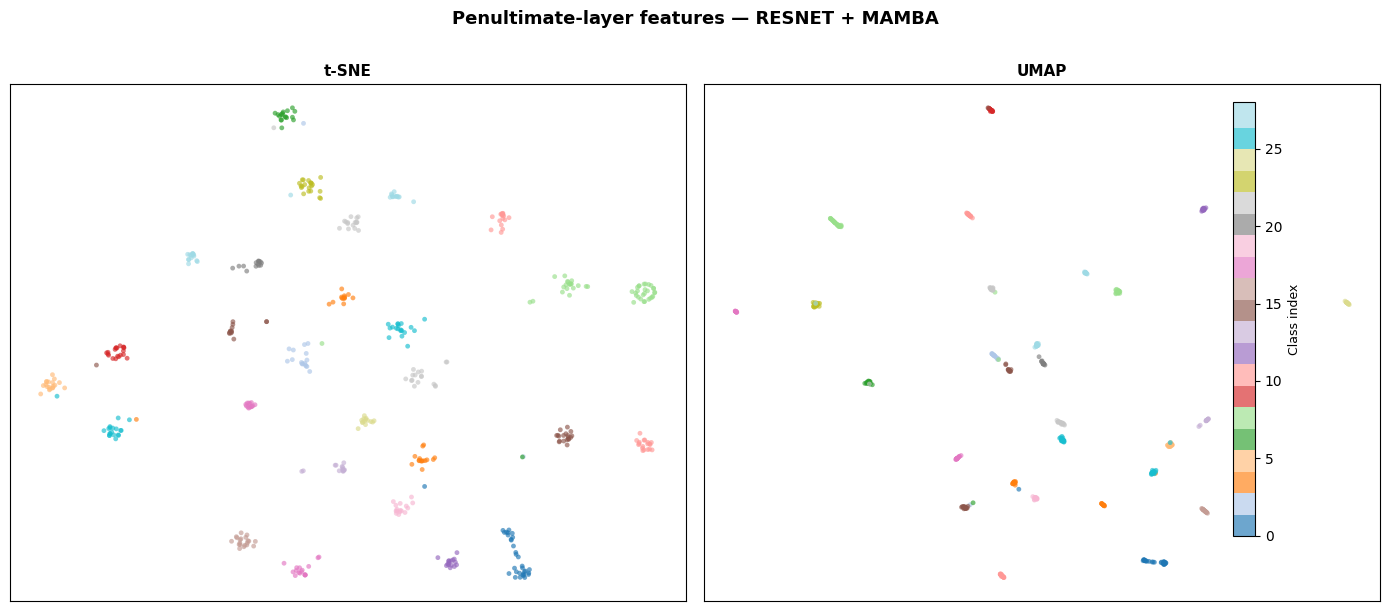


Extracting features: VMAMBA + MAMBA
  Feature matrix: (500, 128)  |  Labels: (500,)
  Computing t-SNE...
  Computing UMAP...


/home/imvikranth/miniconda3/envs/mamba310/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_40983/405833384.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", num_classes)
/tmp/ipykernel_40983/405833384.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


  Saved → vmamba_mamba_features.png


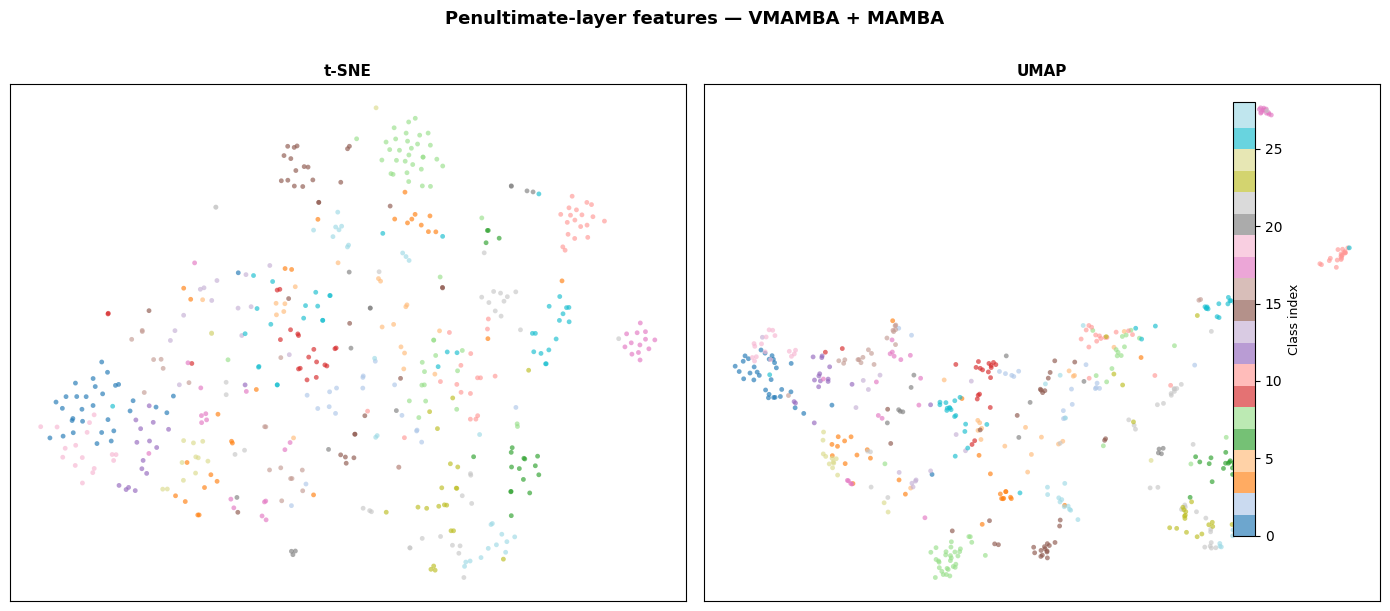

In [21]:
# Compute features + projections once — reused in the comparison grid below
projections = {}   # enc → {"feats", "labels", "tsne", "umap"}

for enc, model in trained_models.items():
    tag = f"{enc.upper()} + MAMBA"
    print(f"\nExtracting features: {tag}")

    # Pull model back to GPU just for inference, then back to CPU
    model.to(device)
    feats, labels = extract_features(model, val_loader, max_samples=VIZ_MAX_SAMPLES)
    model.cpu()
    torch.cuda.empty_cache()
    print(f"  Feature matrix: {feats.shape}  |  Labels: {labels.shape}")

    print(f"  Computing t-SNE...")
    tsne_2d = TSNE
    tsne_2d = TSNE(
        n_components=2, perplexity=30, max_iter=1000,
        random_state=42, init="pca"
    ).fit_transform(feats)

    print(f"  Computing UMAP...")
    umap_2d = umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1, random_state=42
    ).fit_transform(feats)

    projections[enc] = dict(feats=feats, labels=labels, tsne=tsne_2d, umap=umap_2d)

    # ── Per-model t-SNE + UMAP side-by-side plot ──────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Penultimate-layer features — {tag}",
                 fontsize=13, fontweight="bold", y=1.01)

    cmap = cm.get_cmap("tab20", num_classes)

    for ax, proj_2d, method in zip(axes, [tsne_2d, umap_2d], ["t-SNE", "UMAP"]):
        sc = ax.scatter(
            proj_2d[:, 0], proj_2d[:, 1],
            c=labels, cmap=cmap,
            s=12, alpha=0.65, linewidths=0,
        )
        ax.set_title(method, fontsize=11, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])

    cbar = fig.colorbar(sc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label("Class index", fontsize=9)

    plt.tight_layout()
    fname = f"{enc}_mamba_features.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    print(f"  Saved → {fname}")
    plt.show()
    plt.close(fig)


## 11 · Side-by-Side Comparison Across All Three Models

Plot all six projections (3 models × 2 methods) in one figure for easy comparison.

/tmp/ipykernel_40983/3467227146.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", num_classes)
/tmp/ipykernel_40983/3467227146.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved → all_models_features_comparison.png


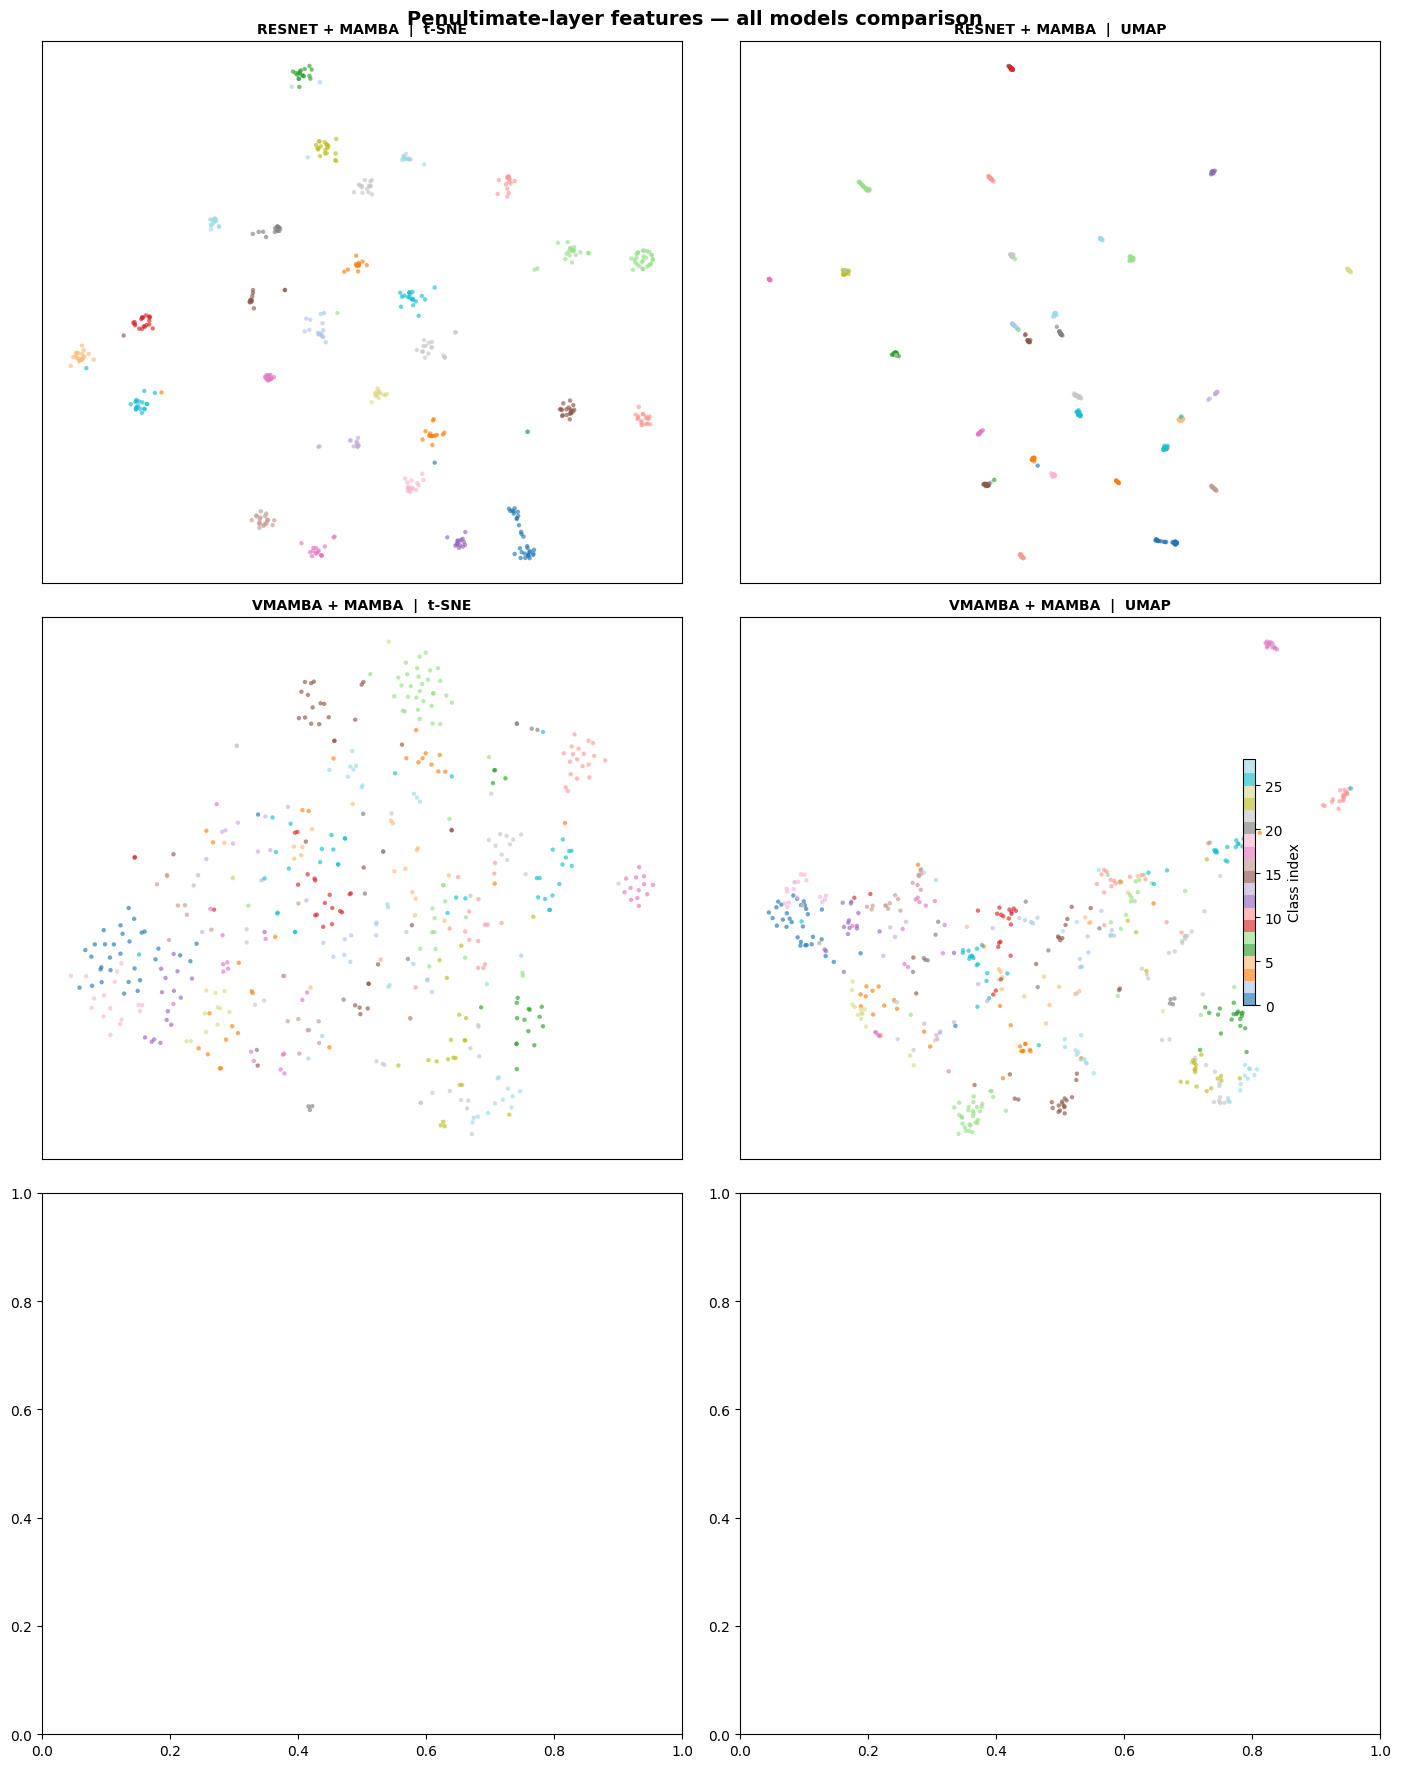

In [25]:
# Reuse already-computed projections — no extra t-SNE / UMAP passes
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
fig.suptitle("Penultimate-layer features — all models comparison",
             fontsize=14, fontweight="bold")

cmap = cm.get_cmap("tab20", num_classes)
sc_ref = None   # keep last scatter handle for shared colorbar

#Overriding and removing VIT
CONFIGS = ['resnet','vmamba']

for row, enc in enumerate(CONFIGS):
    proj = projections[enc]
    for col, (key, method) in enumerate([("tsne", "t-SNE"), ("umap", "UMAP")]):
        ax = axes[row, col]
        sc_ref = ax.scatter(
            proj[key][:, 0], proj[key][:, 1],
            c=proj["labels"], cmap=cmap,
            s=10, alpha=0.65, linewidths=0,
        )
        ax.set_title(f"{enc.upper()} + MAMBA  |  {method}",
                     fontsize=10, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])

fig.colorbar(sc_ref, ax=axes[:, 1].tolist(), fraction=0.025, pad=0.03,
             label="Class index")
plt.tight_layout()
plt.savefig("all_models_features_comparison.png", dpi=150, bbox_inches="tight")
print("Saved → all_models_features_comparison.png")
plt.show()
plt.close(fig)
